In [1]:
# Import the libraries used for data handling, statistics, and visualisation.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

# Configure readable notebook plots.
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
TARGET = "y"
DATA_PATH = Path("Bank_Marketing_Full_Data.csv")

print("Libraries imported successfully.")
print("Notebook working directory:", Path.cwd())

Libraries imported successfully.
Notebook working directory: /content


In [2]:
# Locate the CSV in the notebook folder. Change DATA_PATH if necessary.
if not DATA_PATH.exists():
    candidates = list(Path.cwd().glob("*.csv"))
    print("CSV files found in the notebook folder:", [p.name for p in candidates])
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put Bank_Marketing_Full_Data.csv "
        "beside this notebook or update DATA_PATH."
    )

# sep=None with the Python engine detects the delimiter from the file.
df = pd.read_csv(DATA_PATH, sep=None, engine="python")

# Remove accidental spaces from column names and text values.
df.columns = df.columns.astype(str).str.strip()
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].astype("string").str.strip()

print("Loaded:", DATA_PATH.resolve())
print("Shape:", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

Loaded: /content/Bank_Marketing_Full_Data.csv
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,unknown,16,may,192,1,-1,0,unknown,no
9928,47,services,single,secondary,no,3644,no,no,unknown,9,jun,83,2,-1,0,unknown,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,unknown,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,unknown,no


In [3]:
# Check basic structure and target availability.
assert TARGET in df.columns, f"Target column '{TARGET}' is missing."

n_rows, n_columns = df.shape
n_input_features = n_columns - 1

print(f"Instances: {n_rows:,}")
print(f"Total columns including target: {n_columns}")
print(f"Input features excluding target: {n_input_features}")
print("Target:", TARGET)

eligibility = pd.DataFrame({
    "Assignment requirement": ["At least 500 instances", "At least 12 input features", "Classification target present"],
    "Observed": [n_rows, n_input_features, TARGET in df.columns],
    "Pass": [n_rows >= 500, n_input_features >= 12, TARGET in df.columns]
})
display(eligibility)

# Display column names and inferred data types.
display(pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "unique_values": [df[c].nunique(dropna=True) for c in df.columns],
    "missing_values": [df[c].isna().sum() for c in df.columns]
}))

Instances: 45,211
Total columns including target: 17
Input features excluding target: 16
Target: y


,Assignment requirement,Observed,Pass
0,At least 500 instances,45211,True
1,At least 12 input features,16,True
2,Classification target present,True,True


,column,dtype,unique_values,missing_values
0,age,int64,77,0
1,job,string,12,0
2,marital,string,3,0
3,education,string,4,0
4,default,string,2,0
5,balance,int64,7168,0
6,housing,string,2,0
7,loan,string,2,0
8,contact,string,3,0
9,day,int64,31,0


In [4]:
# Count missing values and exact duplicate rows.
missing_summary = df.isna().sum().sort_values(ascending=False)
print("Total missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(missing_summary.to_frame("missing_count"))

# Count blank strings and literal 'unknown' values in each column.
quality_rows = []
for column in df.columns:
    series = df[column]
    blank_count = int((series.astype("string").str.strip() == "").fillna(False).sum())
    unknown_count = int((series.astype("string").str.lower() == "unknown").fillna(False).sum())
    quality_rows.append({
        "column": column,
        "blank_strings": blank_count,
        "literal_unknown": unknown_count
    })
display(pd.DataFrame(quality_rows).set_index("column"))

# Inspect exact duplicate records without removing anything during EDA.
if df.duplicated().any():
    display(df.loc[df.duplicated(keep=False)].sort_values(list(df.columns)).head(20))

Total missing cells: 0
Exact duplicate rows: 0


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


,blank_strings,literal_unknown
column,,
age,0,0
job,0,288
marital,0,0
education,0,1857
default,0,0
balance,0,0
housing,0,0
loan,0,0
contact,0,13020


In [5]:
# Ensure the target is treated as a categorical label for EDA.
df[TARGET] = df[TARGET].astype("string").str.lower()

numeric_features = df.drop(columns=[TARGET]).select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in df.columns if c != TARGET and c not in numeric_features]

print("Numerical input features:", numeric_features)
print("Categorical input features:", categorical_features)
print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

# Show descriptive statistics for numerical and categorical columns.
display(df[numeric_features].describe().T)
display(df[categorical_features + [TARGET]].describe().T)

Numerical input features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical input features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Number of numerical features: 7
Number of categorical features: 9


,count,mean,std,min,25%,50%,75%,max
age,"45,211.0000",40.9362,10.6188,18.0000,33.0000,39.0000,48.0000,95.0000
balance,"45,211.0000","1,362.2721","3,044.7658","-8,019.0000",72.0000,448.0000,"1,428.0000","102,127.0000"
day,"45,211.0000",15.8064,8.3225,1.0000,8.0000,16.0000,21.0000,31.0000
duration,"45,211.0000",258.1631,257.5278,0.0000,103.0000,180.0000,319.0000,"4,918.0000"
campaign,"45,211.0000",2.7638,3.0980,1.0000,1.0000,2.0000,3.0000,63.0000
pdays,"45,211.0000",40.1978,100.1287,-1.0000,-1.0000,-1.0000,-1.0000,871.0000
previous,"45,211.0000",0.5803,2.3034,0.0000,0.0000,0.0000,0.0000,275.0000


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


,count,percentage
y,,
no,39922,88.3015
yes,5289,11.6985


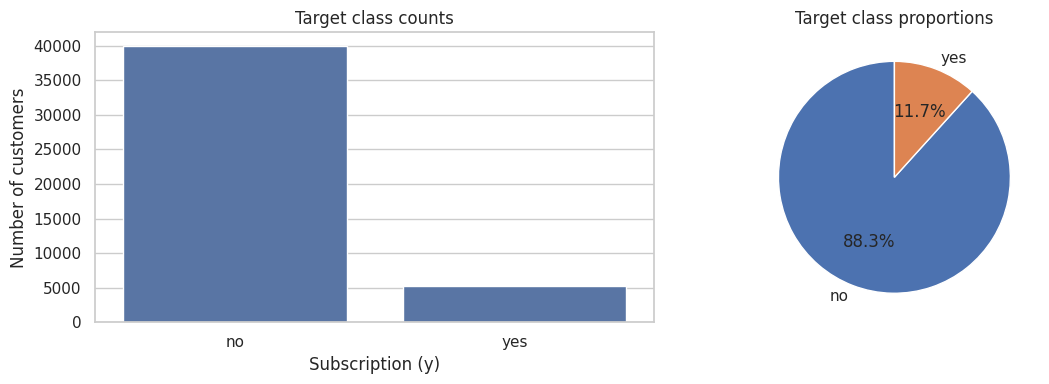

Observed target labels: ['no', 'yes']


In [6]:
# Print target counts and percentages, and plot their distribution.
target_counts = df[TARGET].value_counts(dropna=False)
target_percentages = df[TARGET].value_counts(normalize=True, dropna=False) * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=TARGET, order=target_counts.index, ax=axes[0])
axes[0].set_title("Target class counts")
axes[0].set_xlabel("Subscription (y)")
axes[0].set_ylabel("Number of customers")

axes[1].pie(target_counts.values, labels=target_counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Target class proportions")
plt.tight_layout()
plt.show()

print("Observed target labels:", sorted(df[TARGET].dropna().unique().tolist()))

In [7]:
# Calculate class-wise numerical summaries and a univariate rank-test table.
numeric_summary_by_target = df.groupby(TARGET)[numeric_features].agg(["mean", "median", "std"])
display(numeric_summary_by_target)

numeric_test_rows = []
for feature in numeric_features:
    no_values = df.loc[df[TARGET] == "no", feature].dropna()
    yes_values = df.loc[df[TARGET] == "yes", feature].dropna()

    if len(no_values) and len(yes_values):
        statistic, p_value = mannwhitneyu(no_values, yes_values, alternative="two-sided")
    else:
        statistic, p_value = np.nan, np.nan

    numeric_test_rows.append({
        "feature": feature,
        "median_no": no_values.median(),
        "median_yes": yes_values.median(),
        "mean_no": no_values.mean(),
        "mean_yes": yes_values.mean(),
        "mann_whitney_p_value": p_value
    })

numeric_target_analysis = pd.DataFrame(numeric_test_rows).sort_values("mann_whitney_p_value")
display(numeric_target_analysis)

age                    balance                         day          \
       mean  median     std       mean   median        std    mean  median   
y                                                                            
no  40.8390 39.0000 10.1727 1,303.7150 417.0000 2,974.1955 15.8923 16.0000   
yes 41.6701 38.0000 13.4978 1,804.2679 733.0000 3,501.1048 15.1583 15.0000   

           duration                   campaign                 pdays          \
       std     mean   median      std     mean median    std    mean  median   
y                                                                              
no  8.2947 221.1828 164.0000 207.3832   2.8464 2.0000 3.2128 36.4214 -1.0000   
yes 8.5019 537.2946 426.0000 392.5253   2.1410 2.0000 1.9218 68.7030 -1.0000   

             previous                
         std     mean median    std  
y                                    
no   96.7571   0.5022 0.0000 2.2568  
yes 118.8223   1.1704 0.0000 2.5533

,feature,median_no,median_yes,mean_no,mean_yes,mann_whitney_p_value
3,duration,164.0000,426.0000,221.1828,537.2946,0.0000
6,previous,0.0000,0.0000,0.5022,1.1704,0.0000
5,pdays,-1.0000,-1.0000,36.4214,68.7030,0.0000
1,balance,417.0000,733.0000,"1,303.7150","1,804.2679",0.0000
4,campaign,2.0000,2.0000,2.8464,2.1410,0.0000
2,day,16.0000,15.0000,15.8923,15.1583,0.0000
0,age,39.0000,38.0000,40.8390,41.6701,0.0628


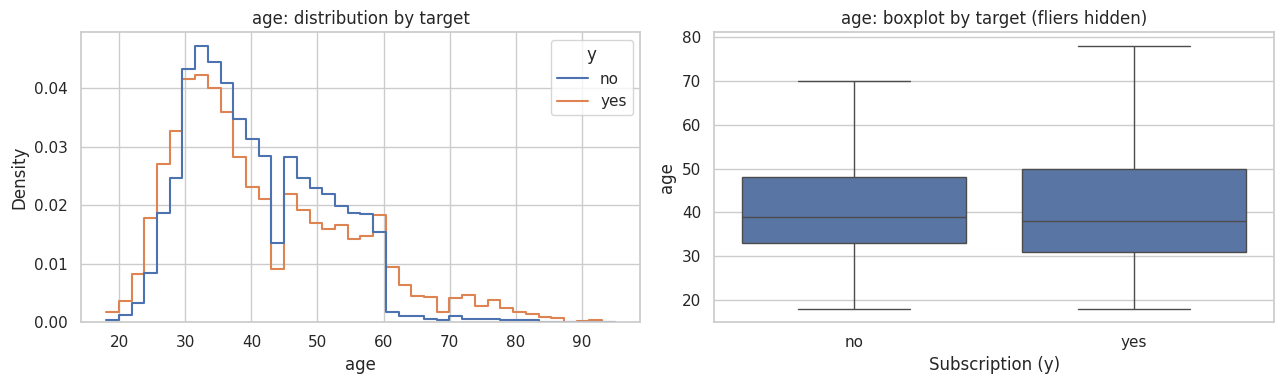

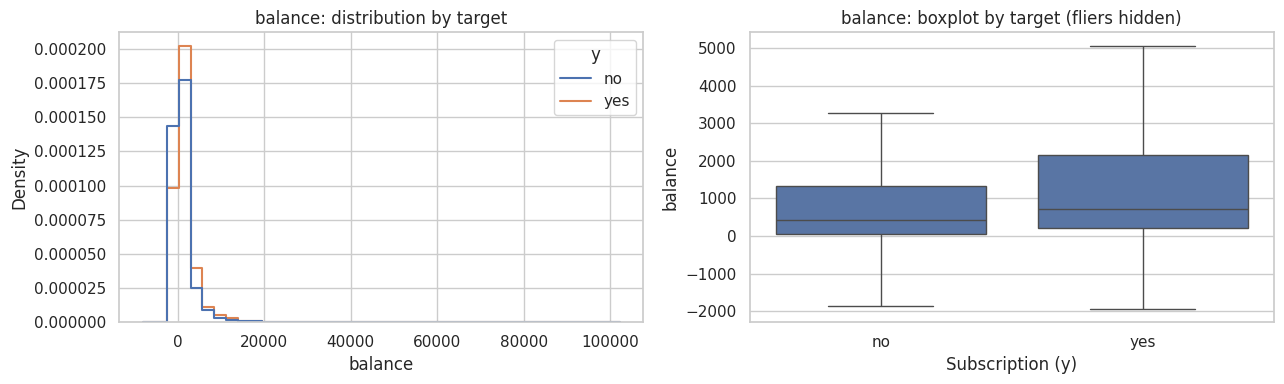

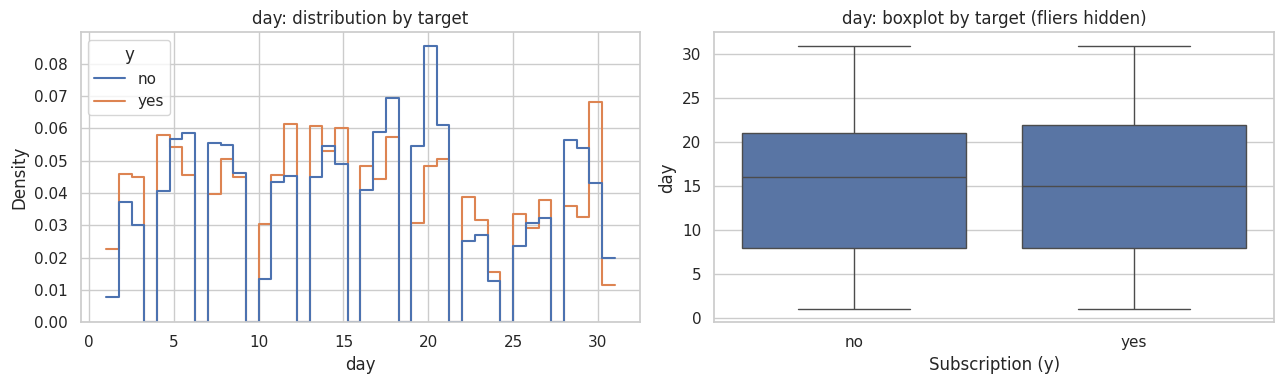

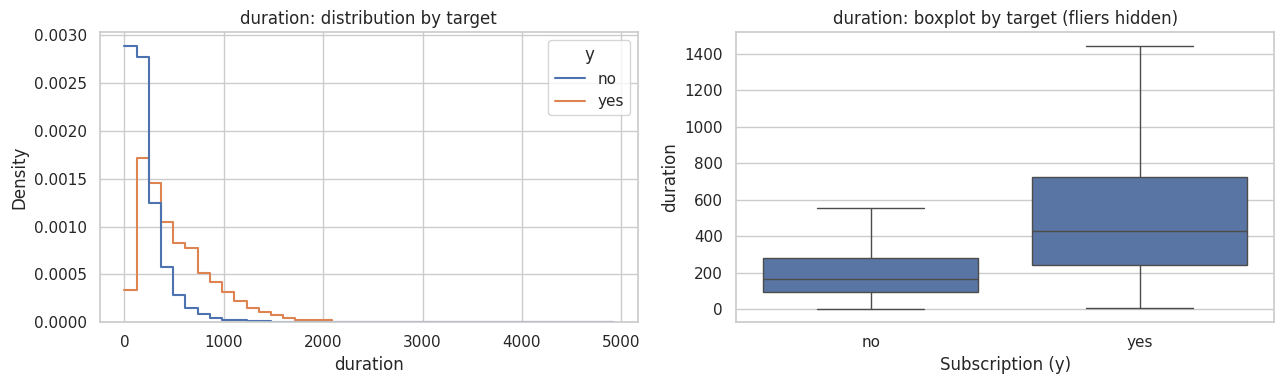

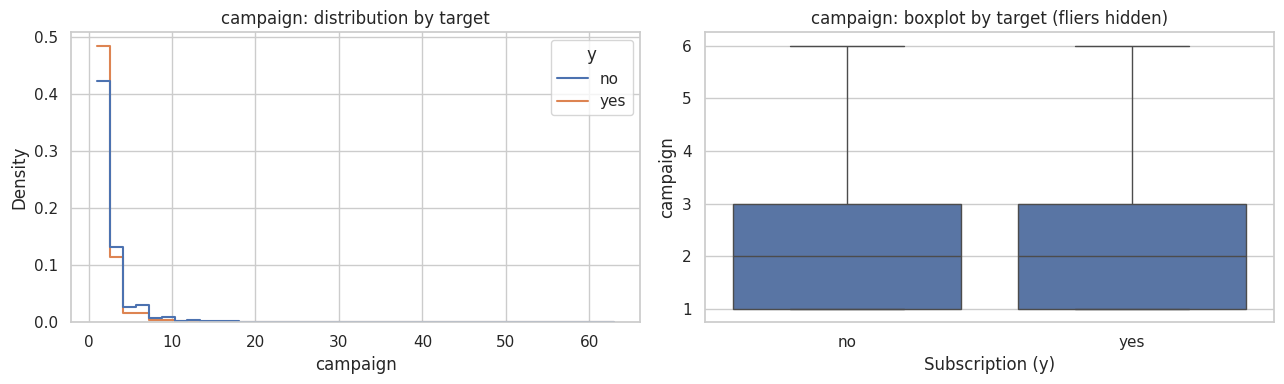

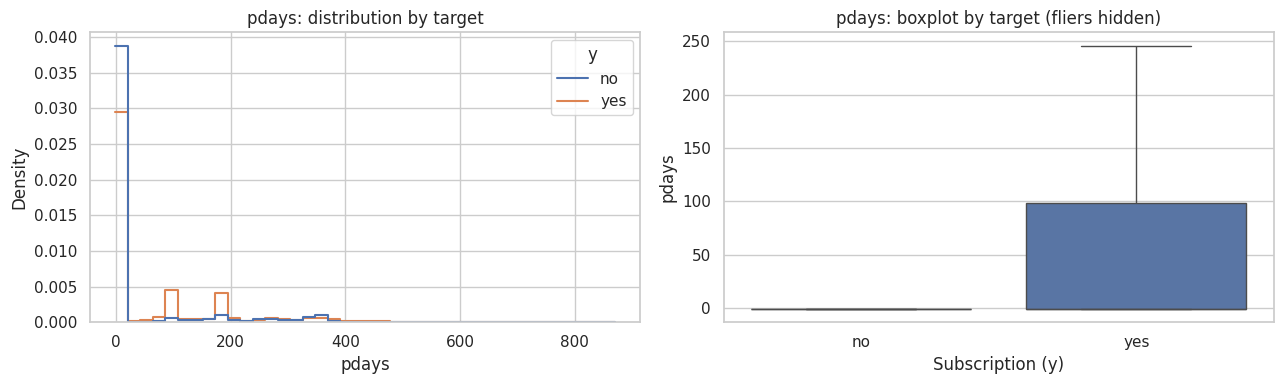

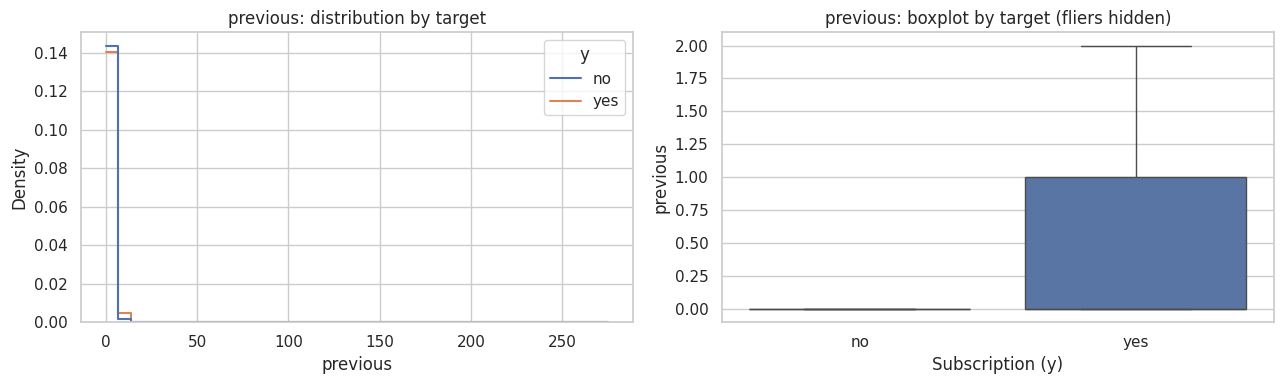

In [8]:
# Draw a distribution plot for each numerical feature, grouped by target.
for feature in numeric_features:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    sns.histplot(
        data=df, x=feature, hue=TARGET, stat="density",
        common_norm=False, element="step", fill=False,
        bins=40, ax=axes[0]
    )
    axes[0].set_title(f"{feature}: distribution by target")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Density")

    sns.boxplot(data=df, x=TARGET, y=feature, showfliers=False, ax=axes[1])
    axes[1].set_title(f"{feature}: boxplot by target (fliers hidden)")
    axes[1].set_xlabel("Subscription (y)")
    axes[1].set_ylabel(feature)

    plt.tight_layout()
    plt.show()

,min,max,skewness,zero_count,negative_count
previous,0,275,41.8465,36954,0
balance,-8019,102127,8.3603,3514,3766
campaign,1,63,4.8987,0,0
duration,0,4918,3.1443,3,0
pdays,-1,871,2.6157,0,36954
age,18,95,0.6848,0,0
day,1,31,0.0931,0,0


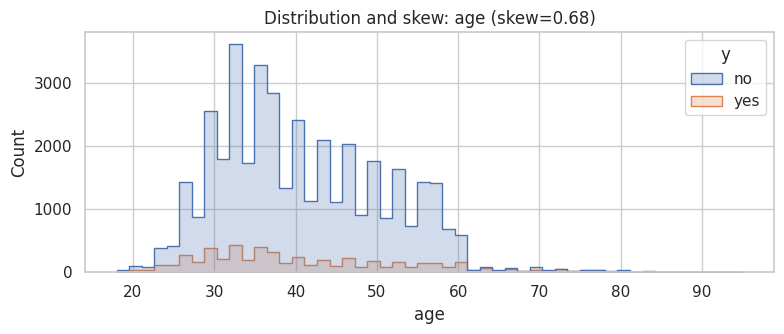

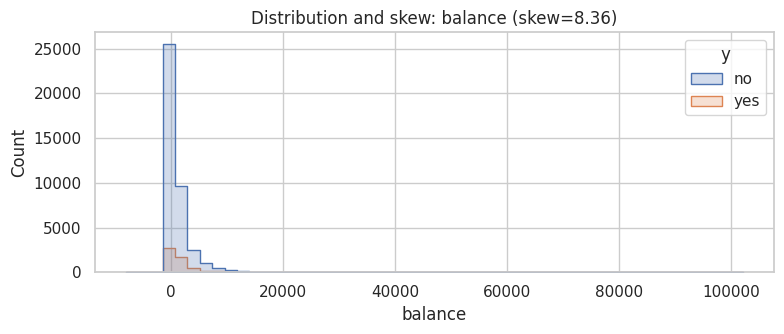

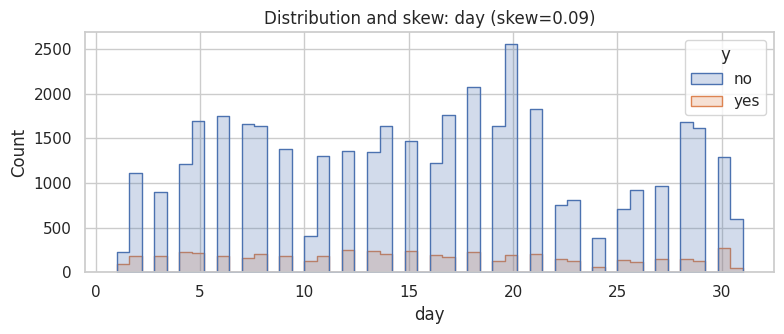

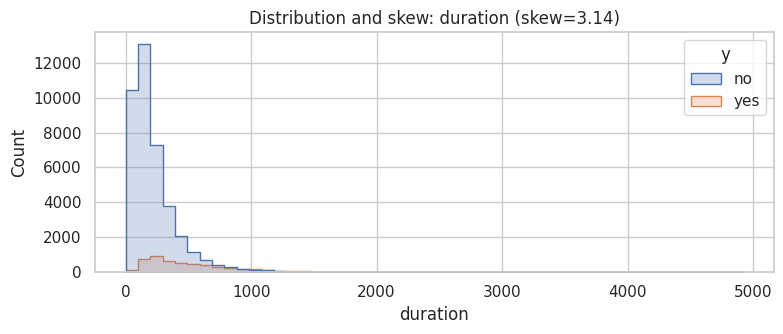

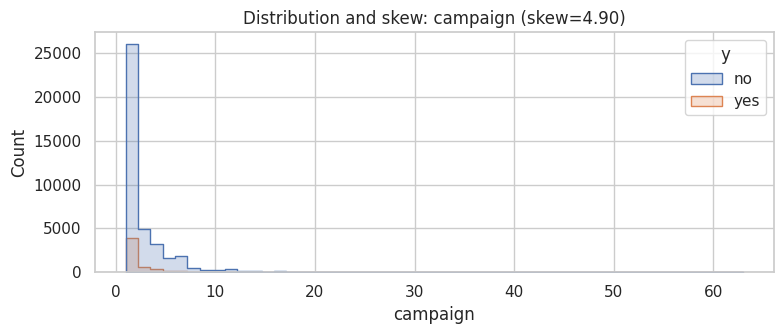

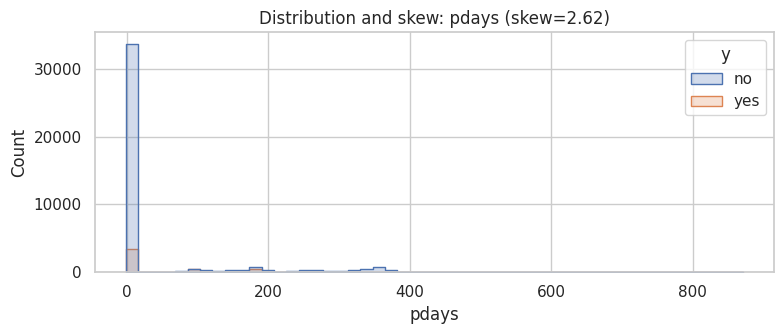

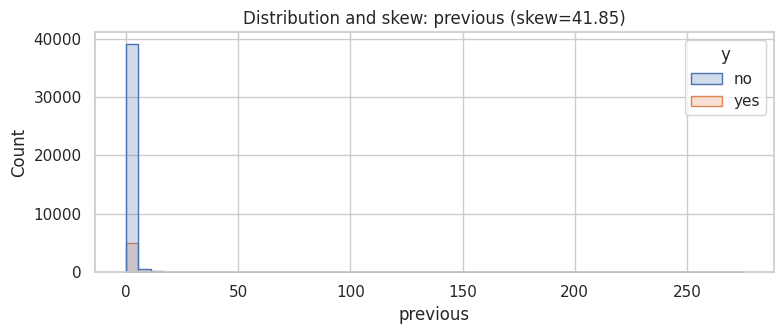

In [9]:
# Summarise range, skewness, and zero/negative values for numerical features.
numeric_shape = pd.DataFrame({
    "min": df[numeric_features].min(),
    "max": df[numeric_features].max(),
    "skewness": df[numeric_features].skew(),
    "zero_count": (df[numeric_features] == 0).sum(),
    "negative_count": (df[numeric_features] < 0).sum()
}).sort_values("skewness", key=lambda s: s.abs(), ascending=False)
display(numeric_shape)

# Visualise numerical feature distributions with a log-scaled y-axis where useful.
for feature in numeric_features:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    sns.histplot(data=df, x=feature, hue=TARGET, bins=50, element="step",
                 stat="count", common_norm=False, ax=ax)
    ax.set_title(f"Distribution and skew: {feature} (skew={df[feature].skew():.2f})")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
    plt.tight_layout()
    plt.show()

,count,min,median,mean,max
y,,,,,
no,39922,-1,-1.0000,36.4214,871
yes,5289,-1,-1.0000,68.7030,854


,sum,mean,percentage
y,,,
no,33570,0.8409,84.0890
yes,3384,0.6398,63.9818


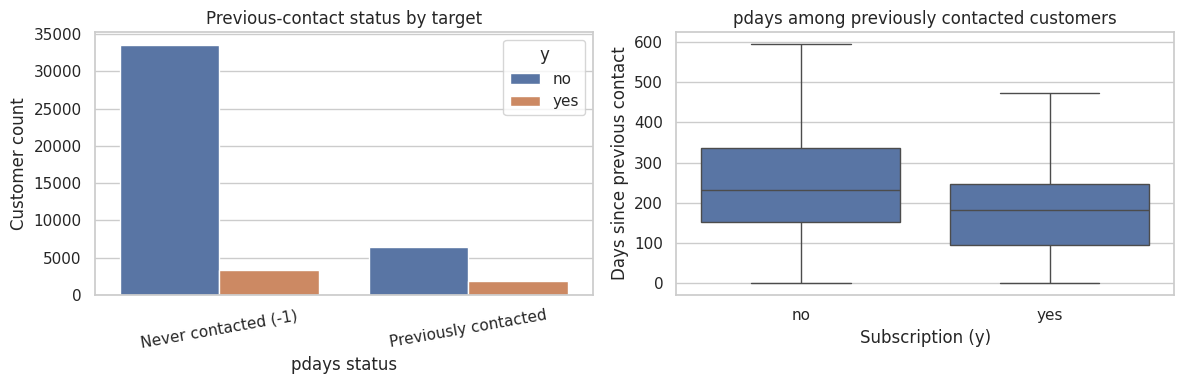

In [10]:
# Inspect pdays and its relationship with the target.
if "pdays" in df.columns:
    pdays_summary = df.groupby(TARGET)["pdays"].agg(
        ["count", "min", "median", "mean", "max"]
    )
    display(pdays_summary)

    pdays_sentinel = df.assign(
        never_previously_contacted=(df["pdays"] == -1).astype(int)
    ).groupby(TARGET)["never_previously_contacted"].agg(["sum", "mean"])
    pdays_sentinel["percentage"] = 100 * pdays_sentinel["mean"]
    display(pdays_sentinel)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(data=df.assign(pdays_status=np.where(df["pdays"] == -1,
                    "Never contacted (-1)", "Previously contacted")),
                  x="pdays_status", hue=TARGET, ax=axes[0])
    axes[0].set_title("Previous-contact status by target")
    axes[0].set_xlabel("pdays status")
    axes[0].set_ylabel("Customer count")
    axes[0].tick_params(axis="x", rotation=10)

    sns.boxplot(data=df.loc[df["pdays"] >= 0], x=TARGET, y="pdays",
                showfliers=False, ax=axes[1])
    axes[1].set_title("pdays among previously contacted customers")
    axes[1].set_xlabel("Subscription (y)")
    axes[1].set_ylabel("Days since previous contact")
    plt.tight_layout()
    plt.show()

In [11]:
# Calculate category-level counts and target rates for every categorical feature.
categorical_target_tables = {}

for feature in categorical_features:
    table = pd.crosstab(df[feature].fillna("<missing>"), df[TARGET], dropna=False)
    for label in ["no", "yes"]:
        if label not in table.columns:
            table[label] = 0
    table["total"] = table["no"] + table["yes"]
    table["yes_rate_percent"] = 100 * table["yes"] / table["total"].replace(0, np.nan)
    table = table.sort_values("yes_rate_percent", ascending=False)
    categorical_target_tables[feature] = table

    print(f"Feature: {feature}")
    display(table)

Feature: job


y,no,yes,total,yes_rate_percent
job,,,,
student,669,269,938,28.6780
retired,1748,516,2264,22.7915
unemployed,1101,202,1303,15.5027
management,8157,1301,9458,13.7556
admin.,4540,631,5171,12.2027
self-employed,1392,187,1579,11.8429
unknown,254,34,288,11.8056
technician,6757,840,7597,11.0570
services,3785,369,4154,8.8830


Feature: marital


y,no,yes,total,yes_rate_percent
marital,,,,
single,10878,1912,12790,14.9492
divorced,4585,622,5207,11.9455
married,24459,2755,27214,10.1235


Feature: education


y,no,yes,total,yes_rate_percent
education,,,,
tertiary,11305,1996,13301,15.0064
unknown,1605,252,1857,13.5703
secondary,20752,2450,23202,10.5594
primary,6260,591,6851,8.6265


... (8 outputs left out)

Feature: month


y,no,yes,total,yes_rate_percent
month,,,,
mar,229,248,477,51.9916
dec,114,100,214,46.7290
sep,310,269,579,46.4594
oct,415,323,738,43.7669
apr,2355,577,2932,19.6794
feb,2208,441,2649,16.6478
aug,5559,688,6247,11.0133
jun,4795,546,5341,10.2228
nov,3567,403,3970,10.1511


Feature: poutcome


y,no,yes,total,yes_rate_percent
poutcome,,,,
success,533,978,1511,64.7253
other,1533,307,1840,16.6848
failure,4283,618,4901,12.6097
unknown,33573,3386,36959,9.1615


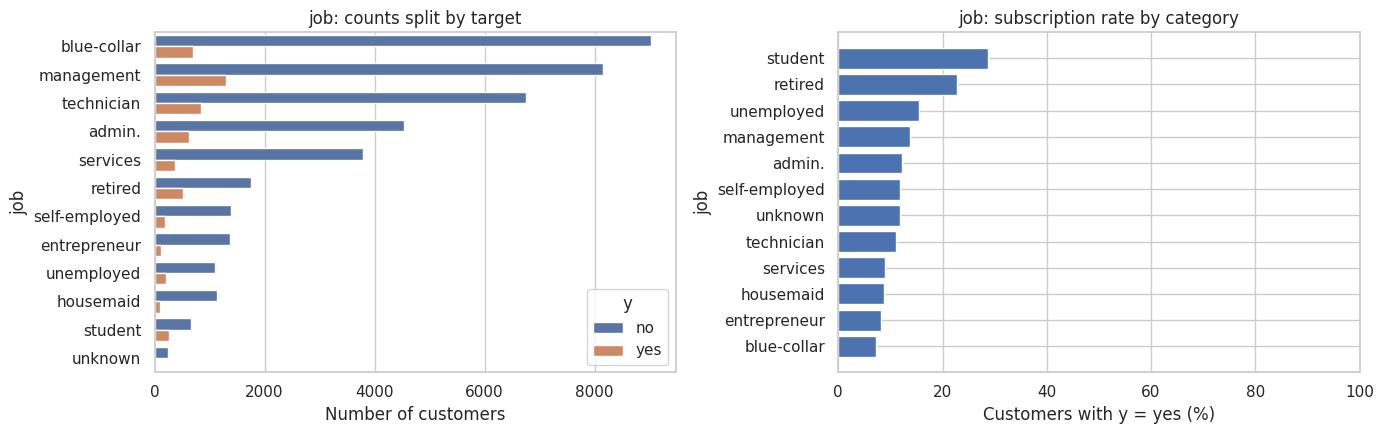

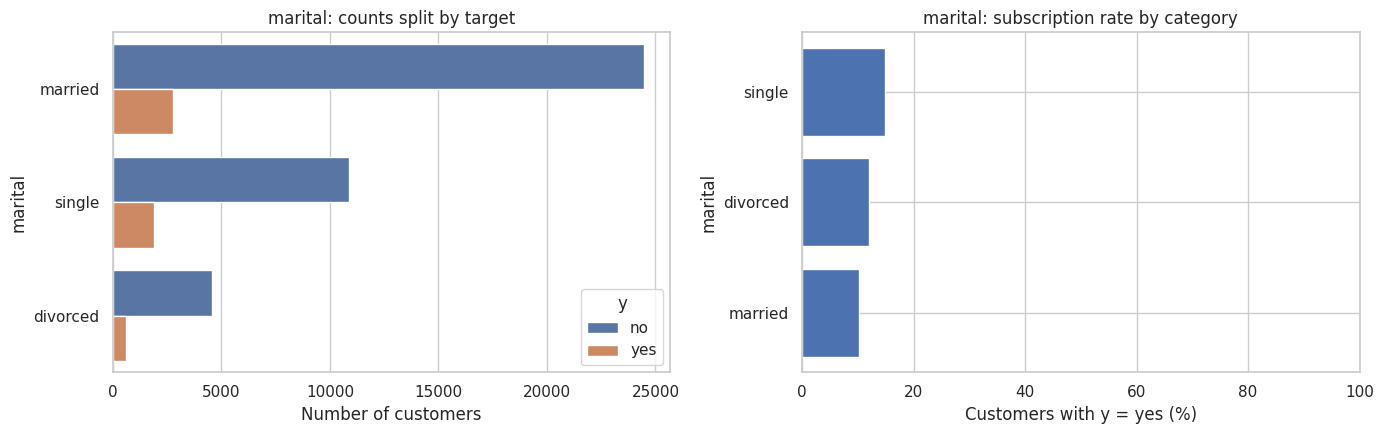

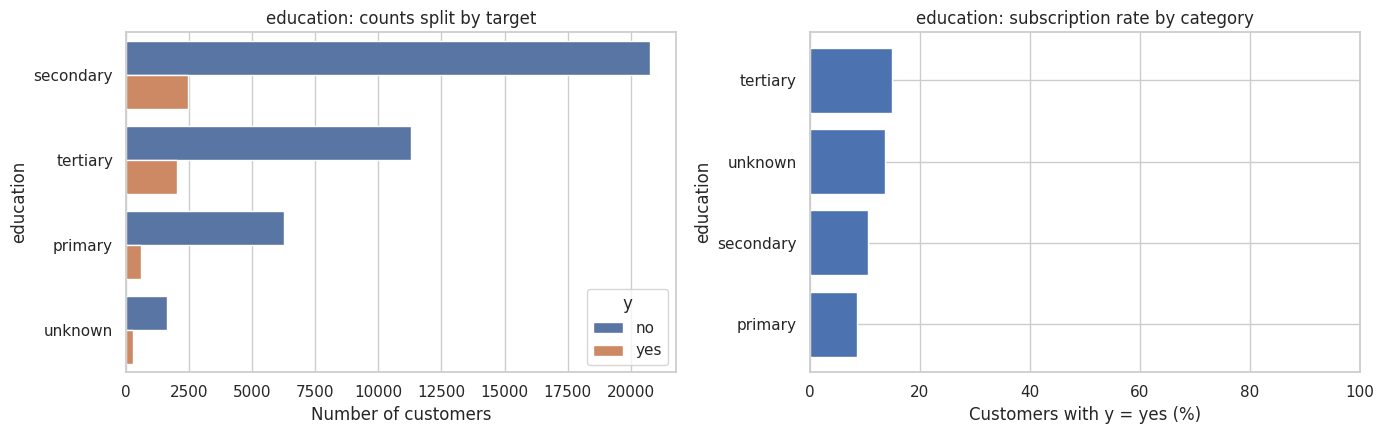

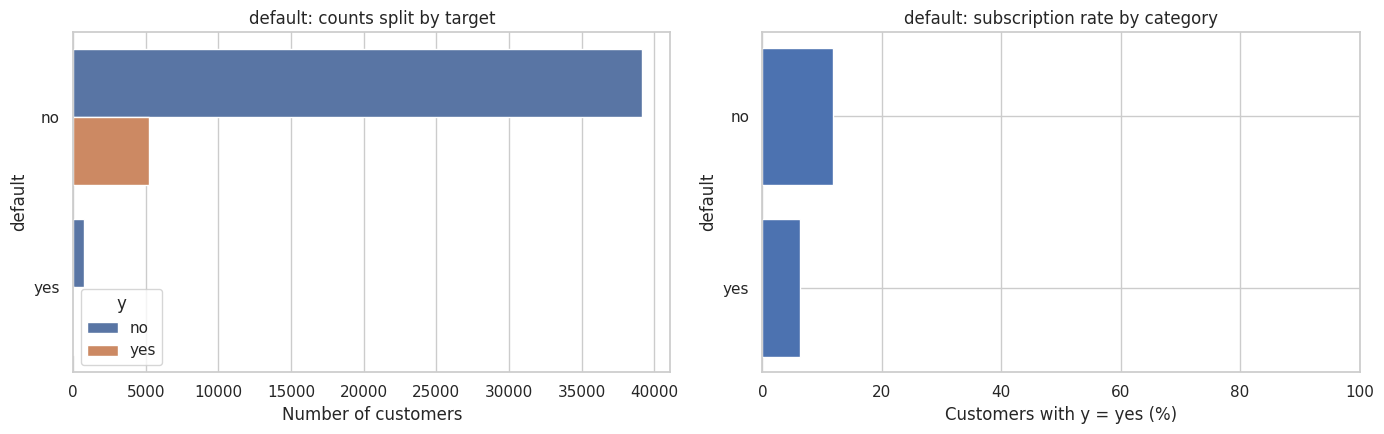

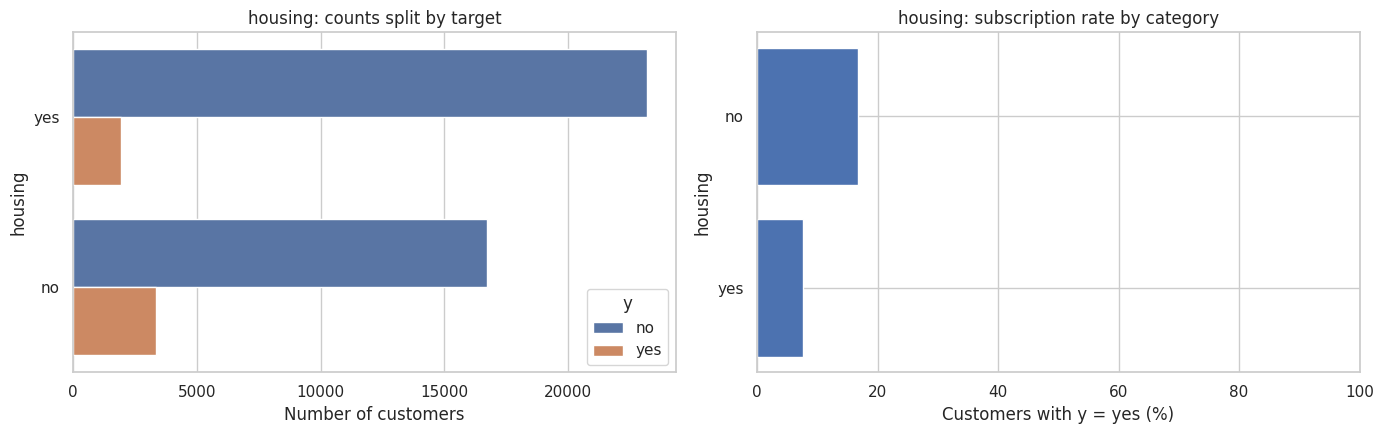

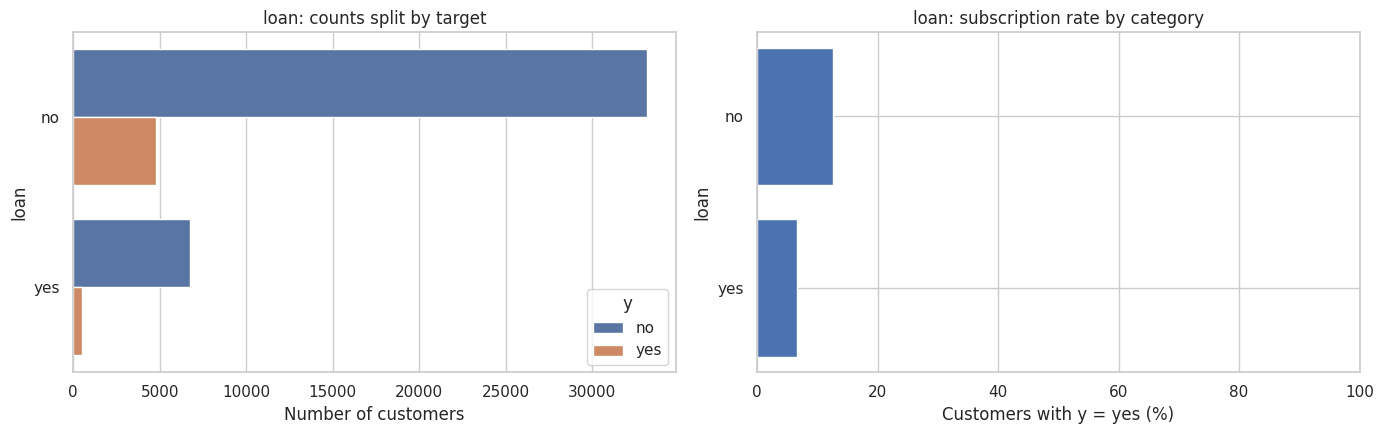

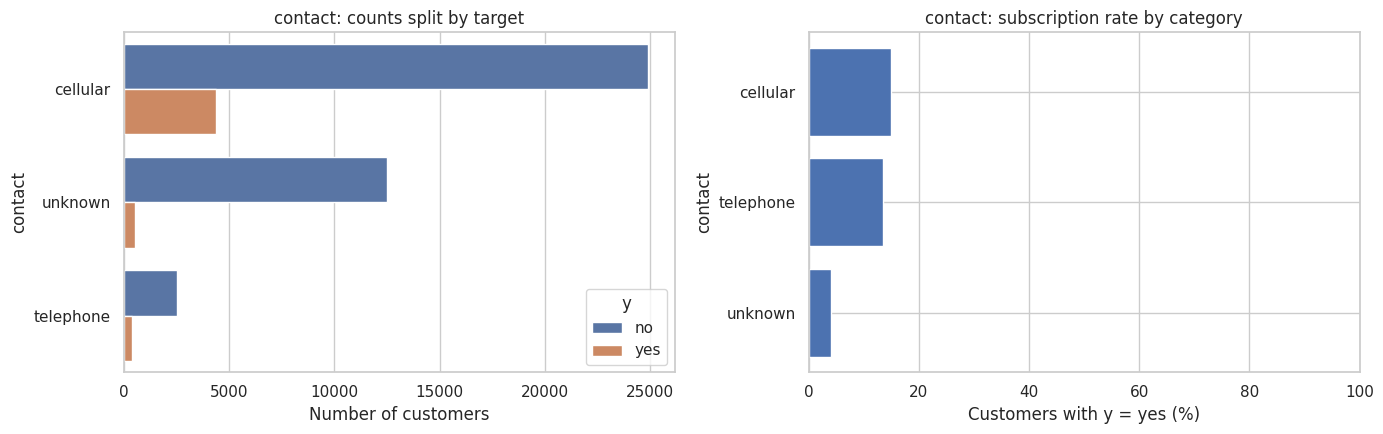

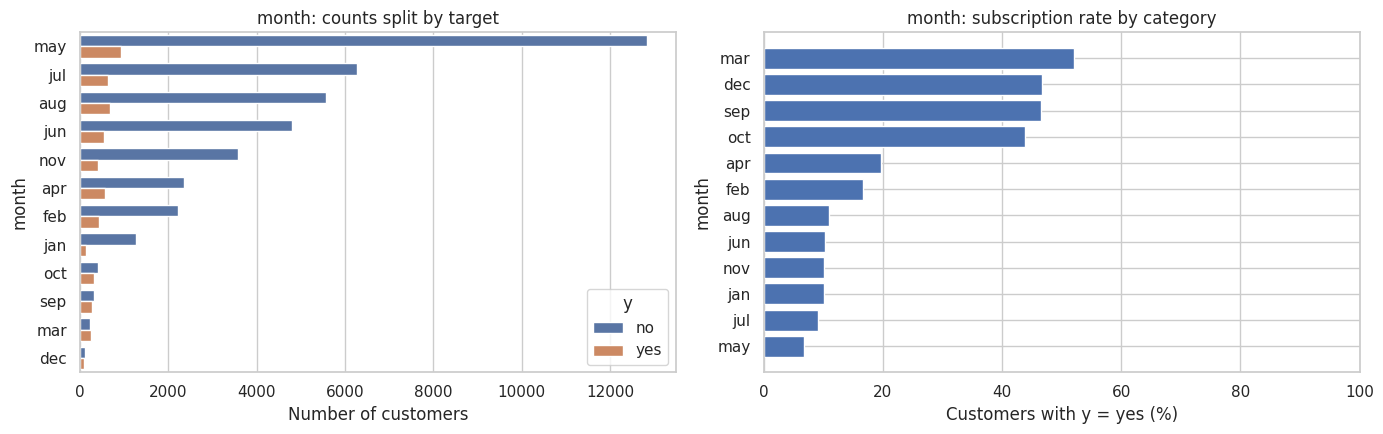

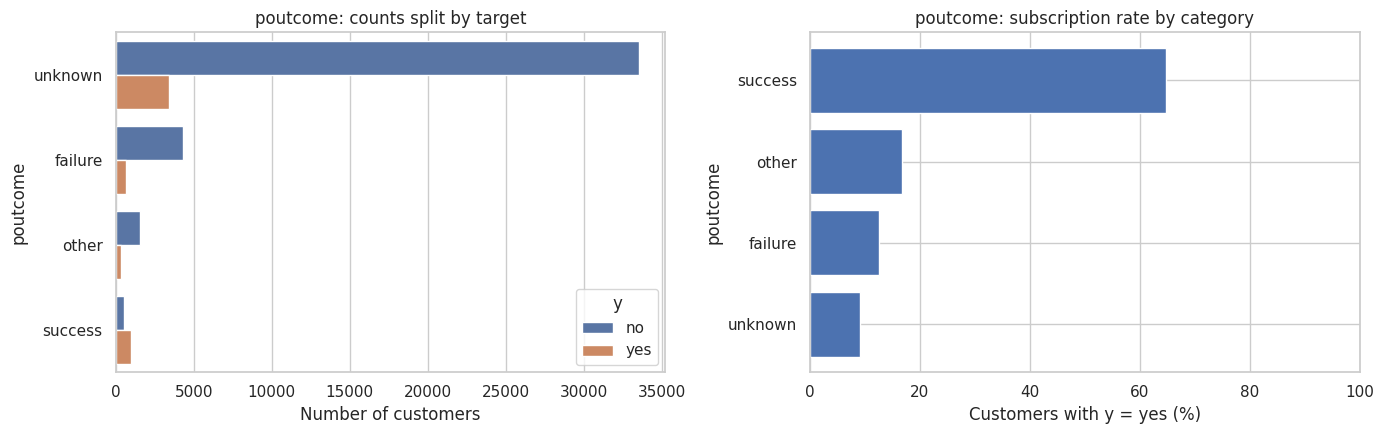

In [12]:
# Plot category counts and within-category subscription rates for every categorical feature.
for feature in categorical_features:
    plot_data = df[[feature, TARGET]].copy()
    plot_data[feature] = plot_data[feature].fillna("<missing>")

    # Order categories by their overall frequency to make plots easier to read.
    category_order = plot_data[feature].value_counts().index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    sns.countplot(data=plot_data, y=feature, hue=TARGET,
                  order=category_order, ax=axes[0])
    axes[0].set_title(f"{feature}: counts split by target")
    axes[0].set_xlabel("Number of customers")
    axes[0].set_ylabel(feature)

    rate_table = categorical_target_tables[feature].sort_values("yes_rate_percent")
    axes[1].barh(rate_table.index.astype(str), rate_table["yes_rate_percent"])
    axes[1].set_title(f"{feature}: subscription rate by category")
    axes[1].set_xlabel("Customers with y = yes (%)")
    axes[1].set_ylabel(feature)
    axes[1].set_xlim(0, 100)

    plt.tight_layout()
    plt.show()

In [13]:
# Compute chi-square tests and Cramer's V for each categorical feature.
categorical_association_rows = []

for feature in categorical_features:
    contingency = pd.crosstab(df[feature].fillna("<missing>"), df[TARGET].fillna("<missing>"))
    if contingency.shape[0] > 1 and contingency.shape[1] > 1:
        chi2, p_value, dof, expected = chi2_contingency(contingency)
        n = contingency.to_numpy().sum()
        min_dimension = min(contingency.shape) - 1
        cramers_v = np.sqrt((chi2 / n) / min_dimension) if min_dimension > 0 and n > 0 else np.nan
    else:
        chi2, p_value, dof, cramers_v = np.nan, np.nan, np.nan, np.nan

    categorical_association_rows.append({
        "feature": feature,
        "chi_square_p_value": p_value,
        "degrees_of_freedom": dof,
        "cramers_v": cramers_v
    })

categorical_association = pd.DataFrame(categorical_association_rows).sort_values(
    "cramers_v", ascending=False
)
display(categorical_association)

,feature,chi_square_p_value,degrees_of_freedom,cramers_v
8,poutcome,0.0000,3,0.3117
7,month,0.0000,11,0.2602
6,contact,0.0000,2,0.1514
4,housing,0.0000,1,0.1391
0,job,0.0000,11,0.1360
2,education,0.0000,3,0.0727
5,loan,0.0000,1,0.0681
1,marital,0.0000,2,0.0659
3,default,0.0000,1,0.0222


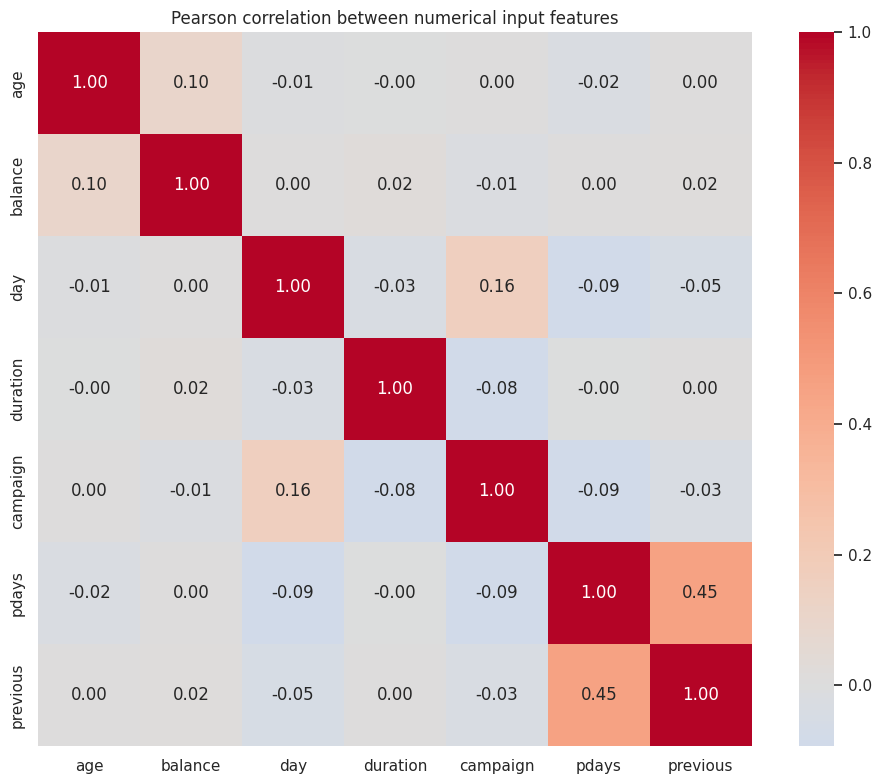

,feature_1,feature_2,correlation


In [14]:
# Plot the Pearson correlation matrix for numerical features.
correlation = df[numeric_features].corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True)
plt.title("Pearson correlation between numerical input features")
plt.tight_layout()
plt.show()

# List pairs with relatively high absolute correlation for review.
high_corr_pairs = []
for i, first in enumerate(numeric_features):
    for second in numeric_features[i + 1:]:
        value = correlation.loc[first, second]
        if abs(value) >= 0.70:
            high_corr_pairs.append({
                "feature_1": first,
                "feature_2": second,
                "correlation": value
            })

display(pd.DataFrame(high_corr_pairs, columns=["feature_1", "feature_2", "correlation"]))

In [15]:
# Define the proposed modelling columns without changing the original EDA dataframe.
EXCLUDED_FEATURES = ["duration"]
proposed_features = [
    column for column in df.columns
    if column != TARGET and column not in EXCLUDED_FEATURES
]

print("Proposed input feature count:", len(proposed_features))
print("Proposed input features:", proposed_features)
print("Excluded features:", EXCLUDED_FEATURES)

# Explicitly check whether any other columns are constant or near-constant.
feature_cardinality = pd.DataFrame({
    "unique_values": df[proposed_features].nunique(dropna=False),
    "unique_fraction": df[proposed_features].nunique(dropna=False) / len(df)
}).sort_values("unique_values")
display(feature_cardinality)

Proposed input feature count: 15
Proposed input features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Excluded features: ['duration']


,unique_values,unique_fraction
housing,2,0.0000
loan,2,0.0000
default,2,0.0000
marital,3,0.0001
contact,3,0.0001
education,4,0.0001
poutcome,4,0.0001
job,12,0.0003
month,12,0.0003
day,31,0.0007


In [16]:
# Confirm the target labels and create a modelling copy for later stages.
observed_labels = set(df[TARGET].dropna().unique())
expected_labels = {"no", "yes"}
if observed_labels != expected_labels:
    raise ValueError(f"Expected target labels {expected_labels}, but found {observed_labels}")

X_initial = df[proposed_features].copy()
y_initial = df[TARGET].map({"no": 0, "yes": 1}).astype("int64")

print("X_initial shape:", X_initial.shape)
print("y_initial shape:", y_initial.shape)
print("Target mapping: no -> 0, yes -> 1")
display(y_initial.value_counts().rename(index={0: "no (0)", 1: "yes (1)"}).to_frame("count"))

X_initial shape: (45211, 15)
y_initial shape: (45211,)
Target mapping: no -> 0, yes -> 1


,count
y,
no (0),39922
yes (1),5289


In [17]:
# Define the feature that must be excluded to avoid information leakage.
EXCLUDED_FEATURES = ["duration"]

# Create the final list of selected input features.
selected_features = [
    column for column in df.columns
    if column != TARGET and column not in EXCLUDED_FEATURES
]

# Create the feature matrix using the selected columns.
X = df[selected_features].copy()

# Create the target vector using the existing binary encoding.
y = df[TARGET].map({"no": 0, "yes": 1}).astype("int64")

# Display the selected features and their count.
print("Selected features:", selected_features)
print("Number of selected features:", len(selected_features))

# Display the excluded features.
print("Excluded features:", EXCLUDED_FEATURES)

# Display the dimensions of the feature matrix and target.
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Verify that duration is not included in the feature matrix.
assert "duration" not in X.columns

# Verify that all 15 selected features are present.
assert X.shape[1] == 15

# Verify that the target contains only binary labels.
assert set(y.unique()) == {0, 1}

Selected features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Number of selected features: 15
Excluded features: ['duration']
Feature matrix shape: (45211, 15)
Target vector shape: (45211,)


In [18]:
# Identify numerical features from the selected feature matrix.
numeric_features_model = (
    X.select_dtypes(include=np.number).columns.tolist()
)

# Identify categorical features from the selected feature matrix.
categorical_features_model = [
    column for column in X.columns
    if column not in numeric_features_model
]

# Display the numerical feature names.
print("Numerical features:", numeric_features_model)

# Display the categorical feature names.
print("Categorical features:", categorical_features_model)

# Display the total number of features in each group.
print("Number of numerical features:", len(numeric_features_model))
print("Number of categorical features:", len(categorical_features_model))


Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Number of numerical features: 6
Number of categorical features: 9


In [19]:

# Import the train-test splitting function.
from sklearn.model_selection import train_test_split

# Split the feature matrix and target into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Selected input features.
    y,                  # Binary target variable.
    test_size=0.20,     # Reserve 20% of observations for testing.
    random_state=42,    # Ensure reproducibility.
    stratify=y          # Preserve target class proportions.
)

# Display the dimensions of the resulting datasets.
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Display the training target distribution.
print("\nTraining target distribution:")
display(
    y_train.value_counts()
    .rename(index={0: "no (0)", 1: "yes (1)"})
    .to_frame("count")
)

# Display the testing target distribution.
print("\nTesting target distribution:")
display(
    y_test.value_counts()
    .rename(index={0: "no (0)", 1: "yes (1)"})
    .to_frame("count")
)

# Display class percentages in the training dataset.
print("\nTraining target percentages:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .rename(index={0: "no (0)", 1: "yes (1)"})
    .to_frame("percentage")
)

# Display class percentages in the testing dataset.
print("\nTesting target percentages:")
display(
    (y_test.value_counts(normalize=True) * 100)
    .rename(index={0: "no (0)", 1: "yes (1)"})
    .to_frame("percentage")
)

X_train shape: (36168, 15)
X_test shape: (9043, 15)
y_train shape: (36168,)
y_test shape: (9043,)

Training target distribution:


,count
y,
no (0),31937
yes (1),4231



Testing target distribution:


,count
y,
no (0),7985
yes (1),1058



Training target percentages:


,percentage
y,
no (0),88.3018
yes (1),11.6982



Testing target percentages:


,percentage
y,
no (0),88.3003
yes (1),11.6997


In [20]:

# Import the numerical and categorical preprocessing tools.
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import the column-wise preprocessing transformer.
from sklearn.compose import ColumnTransformer

# Import Pipeline for organizing preprocessing steps.
from sklearn.pipeline import Pipeline

# Create a numerical preprocessing pipeline.
numeric_transformer = Pipeline(
    steps=[
        # Standardize numerical features using training data statistics.
        ("scaler", StandardScaler())
    ]
)

# Create a categorical preprocessing pipeline.
categorical_transformer = Pipeline(
    steps=[
        # Convert categorical values into binary indicator columns.
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Combine numerical and categorical preprocessing pipelines.
preprocessor = ColumnTransformer(
    transformers=[
        # Apply scaling to numerical features.
        ("num", numeric_transformer, numeric_features_model),

        # Apply one-hot encoding to categorical features.
        ("cat", categorical_transformer, categorical_features_model)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Display the preprocessing configuration.
print("Preprocessing transformer created successfully.")
print(preprocessor)


Preprocessing transformer created successfully.
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['age', 'balance', 'day', 'campaign', 'pdays',
                                  'previous']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'poutcome'])],
                  verbose_feature_names_out=False)


In [21]:

# Fit the preprocessing transformer using training data only.
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the already fitted transformer.
X_test_processed = preprocessor.transform(X_test)

# Retrieve the names of the transformed features.
processed_feature_names = preprocessor.get_feature_names_out()

# Display the dimensions of the processed datasets.
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

# Display the number of generated features.
print("Total processed features:", len(processed_feature_names))

# Display the first few generated feature names.
print("\nFirst 20 processed feature names:")
print(processed_feature_names[:20])

# Verify that both datasets have the same number of features.
assert X_train_processed.shape[1] == X_test_processed.shape[1]

# Verify that the processed feature count matches the feature names.
assert X_train_processed.shape[1] == len(processed_feature_names)

# Verify that no missing values were introduced during preprocessing.
assert not np.isnan(X_train_processed).any()
assert not np.isnan(X_test_processed).any()

# Display successful preprocessing validation.
print("\nPreprocessing validation completed successfully.")


Processed training data shape: (36168, 50)
Processed testing data shape: (9043, 50)
Total processed features: 50

First 20 processed feature names:
['age' 'balance' 'day' 'campaign' 'pdays' 'previous' 'job_admin.'
 'job_blue-collar' 'job_entrepreneur' 'job_housemaid' 'job_management'
 'job_retired' 'job_self-employed' 'job_services' 'job_student'
 'job_technician' 'job_unemployed' 'job_unknown' 'marital_divorced'
 'marital_married']

Preprocessing validation completed successfully.


In [22]:

# Identify the number of numerical features.
num_feature_count = len(numeric_features_model)

# Extract the standardized numerical columns from training data.
scaled_numeric_train = X_train_processed[:, :num_feature_count]

# Calculate the mean of each standardized numerical feature.
scaled_means = scaled_numeric_train.mean(axis=0)

# Calculate the standard deviation of each standardized numerical feature.
scaled_stds = scaled_numeric_train.std(axis=0)

# Create a summary of scaling results.
scaling_summary = pd.DataFrame({
    "feature": numeric_features_model,
    "scaled_mean": scaled_means,
    "scaled_std": scaled_stds
})

# Display the numerical scaling verification results.
display(scaling_summary)

# Verify that the standardized training features have approximately zero means.
assert np.allclose(scaled_means, 0, atol=1e-6)

# Verify that the standardized training features have unit standard deviations.
assert np.allclose(scaled_stds, 1, atol=1e-6)

print("Numerical feature scaling verified successfully.")


,feature,scaled_mean,scaled_std
0,age,-0.0000,1.0000
1,balance,-0.0000,1.0000
2,day,0.0000,1.0000
3,campaign,0.0000,1.0000
4,pdays,-0.0000,1.0000
5,previous,-0.0000,1.0000


Numerical feature scaling verified successfully.


In [23]:
# Display the final training and testing dataset dimensions.
print("Final training dataset:", X_train_processed.shape)
print("Final testing dataset:", X_test_processed.shape)

# Display the training target dimensions.
print("Training target:", y_train.shape)

# Display the testing target dimensions.
print("Testing target:", y_test.shape)

# Verify that the training and testing datasets have matching feature counts.
assert X_train_processed.shape[1] == X_test_processed.shape[1]

# Verify that the training and testing target lengths match their feature rows.
assert len(X_train_processed) == len(y_train)
assert len(X_test_processed) == len(y_test)

# Verify that the original target classes are preserved.
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

# Verify that all processed feature values are finite.
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

# Confirm that the original feature selection has been preserved.
assert "duration" not in X.columns

print("\nAll final preprocessing checks passed successfully.")
print("The datasets are ready for classification model training.")

Final training dataset: (36168, 50)
Final testing dataset: (9043, 50)
Training target: (36168,)
Testing target: (9043,)

All final preprocessing checks passed successfully.
The datasets are ready for classification model training.


In [24]:
# Import the classification algorithms.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Import the evaluation metrics required by the assignment.
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Import pandas for storing and displaying model results.
import pandas as pd

# Import matplotlib and seaborn for confusion matrix visualisations.
import matplotlib.pyplot as plt
import seaborn as sns

# Import time to record model training duration.
import time

print("Classification libraries imported successfully.")

Classification libraries imported successfully.


In [25]:
# Define the five classification models required by the assignment.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": LinearSVC(
        max_iter=10000,
        random_state=42
    )
}

# Display the models selected for training.
print("Classification models selected:")
for model_name in models:
    print("-", model_name)

Classification models selected:
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- Support Vector Machine


In [26]:
# Create a dictionary to store the trained models.
trained_models = {}

# Create a dictionary to store the training time of each model.
training_times = {}

# Train each classification model using the same training dataset.
for model_name, model in models.items():

    # Record the starting time of model training.
    start_time = time.time()

    # Fit the model using the processed training features and target.
    model.fit(X_train_processed, y_train)

    # Calculate the total time taken for training.
    elapsed_time = time.time() - start_time

    # Store the trained model.
    trained_models[model_name] = model

    # Store the training duration.
    training_times[model_name] = elapsed_time

    # Display the training status and time.
    print(f"{model_name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")
    print("-" * 50)

# Confirm that all five models have been trained.
print("\nTotal trained models:", len(trained_models))

Logistic Regression trained successfully.
Training time: 0.42 seconds
--------------------------------------------------
Decision Tree trained successfully.
Training time: 0.57 seconds
--------------------------------------------------
KNN trained successfully.
Training time: 0.01 seconds
--------------------------------------------------
Naive Bayes trained successfully.
Training time: 0.04 seconds
--------------------------------------------------
Support Vector Machine trained successfully.
Training time: 0.17 seconds
--------------------------------------------------

Total trained models: 5


In [27]:
# Create dictionaries to store predictions and evaluation results.
model_predictions = {}
model_scores = {}
evaluation_results = []

# Evaluate every trained model using the same test dataset.
for model_name, model in trained_models.items():

    # Generate predicted class labels for the test dataset.
    y_pred = model.predict(X_test_processed)

    # Store the predicted labels.
    model_predictions[model_name] = y_pred

    # Obtain probability estimates when the model supports them.
    if hasattr(model, "predict_proba"):

        # Extract the probability of the positive class (class 1).
        y_score = model.predict_proba(X_test_processed)[:, 1]

    else:

        # Use decision scores for models such as LinearSVC.
        y_score = model.decision_function(X_test_processed)

    # Store the scores used for ROC-AUC calculation.
    model_scores[model_name] = y_score

    # Calculate the six evaluation metrics.
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_score)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store the evaluation results for this model.
    evaluation_results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    # Display the evaluation results.
    print(f"\nEvaluation results: {model_name}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"AUC       : {auc:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print(f"MCC       : {mcc:.4f}")
    print("-" * 50)


Evaluation results: Logistic Regression
Accuracy  : 0.8933
AUC       : 0.7717
Precision : 0.6632
Recall    : 0.1786
F1 Score  : 0.2815
MCC       : 0.3065
--------------------------------------------------

Evaluation results: Decision Tree
Accuracy  : 0.8309
AUC       : 0.6132
Precision : 0.2982
Recall    : 0.3289
F1 Score  : 0.3128
MCC       : 0.2170
--------------------------------------------------

Evaluation results: KNN
Accuracy  : 0.8874
AUC       : 0.7027
Precision : 0.5529
Recall    : 0.1975
F1 Score  : 0.2911
MCC       : 0.2833
--------------------------------------------------

Evaluation results: Naive Bayes
Accuracy  : 0.8452
AUC       : 0.7514
Precision : 0.3708
Recall    : 0.4641
F1 Score  : 0.4123
MCC       : 0.3271
--------------------------------------------------

Evaluation results: Support Vector Machine
Accuracy  : 0.8932
AUC       : 0.7682
Precision : 0.6513
Recall    : 0.1871
F1 Score  : 0.2907
MCC       : 0.3101
------------------------------------------------

In [28]:
# Convert the evaluation results into a pandas DataFrame.
comparison_df = pd.DataFrame(evaluation_results)

# Arrange the columns in the assignment's required order.
comparison_df = comparison_df[
    [
        "ML Model Name",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1 Score",
        "MCC"
    ]
]

# Display the comparison table with four decimal places.
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8933,0.7717,0.6632,0.1786,0.2815,0.3065
1,Decision Tree,0.8309,0.6132,0.2982,0.3289,0.3128,0.2170
2,KNN,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833
3,Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
4,Support Vector Machine,0.8932,0.7682,0.6513,0.1871,0.2907,0.3101


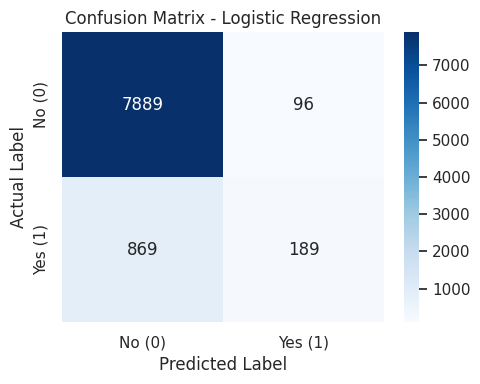

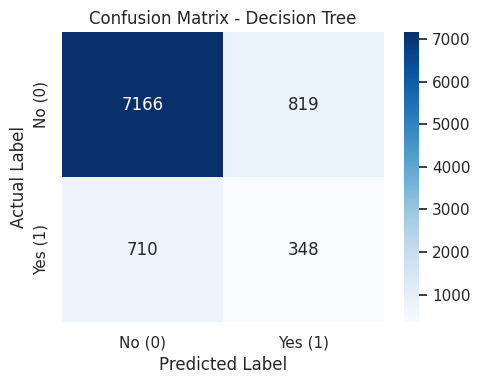

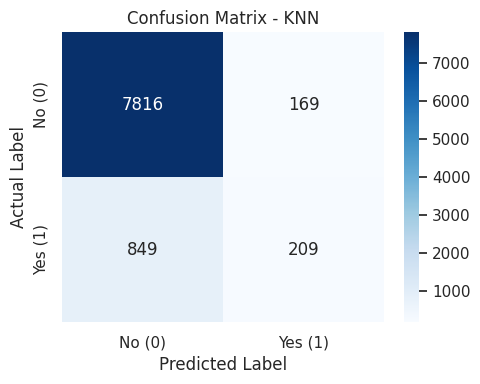

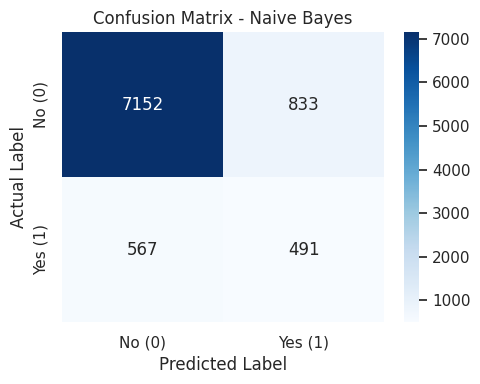

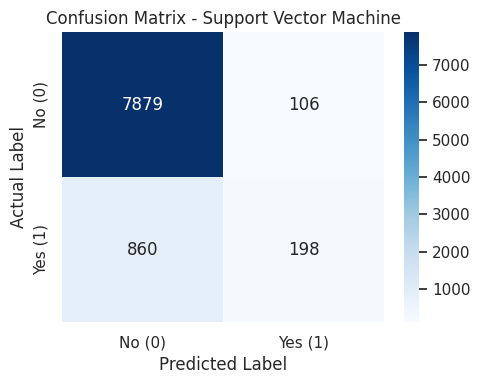

In [29]:
# Generate a separate confusion matrix for each trained model.
for model_name, y_pred in model_predictions.items():

    # Calculate the confusion matrix using the actual and predicted labels.
    cm = confusion_matrix(y_test, y_pred)

    # Create a figure for the confusion matrix.
    plt.figure(figsize=(5, 4))

    # Display the confusion matrix as a heatmap.
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No (0)", "Yes (1)"],
        yticklabels=["No (0)", "Yes (1)"]
    )

    # Add a descriptive plot title.
    plt.title(f"Confusion Matrix - {model_name}")

    # Label the horizontal and vertical axes.
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    # Adjust the layout and display the plot.
    plt.tight_layout()
    plt.show()

In [30]:
# Generate a classification report for every trained model.
for model_name, y_pred in model_predictions.items():

    # Calculate the detailed classification report.
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No", "Yes"],
        zero_division=0
    )

    # Display the report for the current model.
    print(f"\nClassification Report: {model_name}")
    print(report)
    print("-" * 60)


Classification Report: Logistic Regression
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043

------------------------------------------------------------

Classification Report: Decision Tree
              precision    recall  f1-score   support

          No       0.91      0.90      0.90      7985
         Yes       0.30      0.33      0.31      1058

    accuracy                           0.83      9043
   macro avg       0.60      0.61      0.61      9043
weighted avg       0.84      0.83      0.83      9043

------------------------------------------------------------

Classification Report: KNN
              precision    recall  f1-score   support

          No       0.90      0.98      0.94      7985
     

In [31]:
# Import Path for creating and managing folders.
from pathlib import Path

# Import joblib for saving trained machine learning objects.
import joblib

# Create the model directory if it does not already exist.
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory created successfully.")

Model directory created successfully.


In [32]:
# Define filenames for the five trained classification models.
model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

# Save each trained model separately.
for model_name, model in trained_models.items():

    # Get the filename corresponding to the current model.
    filename = model_filenames[model_name]

    # Construct the complete file path.
    file_path = MODEL_DIR / filename

    # Save the trained model.
    joblib.dump(model, file_path)

    # Confirm that the model has been saved.
    print(f"{model_name} saved at: {file_path}")

Logistic Regression saved at: model/logistic_regression.joblib
Decision Tree saved at: model/decision_tree.joblib
KNN saved at: model/knn.joblib
Naive Bayes saved at: model/naive_bayes.joblib
Support Vector Machine saved at: model/support_vector_machine.joblib


In [33]:
# Save the fitted preprocessing object.
preprocessor_path = MODEL_DIR / "preprocessor.joblib"

# Store the fitted scaler and one-hot encoder.
joblib.dump(preprocessor, preprocessor_path)

print("Preprocessor saved successfully.")
print("Saved at:", preprocessor_path)

Preprocessor saved successfully.
Saved at: model/preprocessor.joblib


In [34]:
# Create a copy of the original test features.
test_data = X_test.copy()

# Add the actual target labels to the test dataset.
test_data["y"] = np.asarray(y_test)

# Reset the index for a clean CSV file.
test_data = test_data.reset_index(drop=True)

# Save the test dataset in the project directory.
test_data.to_csv("test_data.csv", index=False)

# Display the saved test dataset information.
print("Test dataset exported successfully.")
print("Test dataset shape:", test_data.shape)
print("Test dataset location: test_data.csv")

# Display the first five rows.
display(test_data.head())

Test dataset exported successfully.
Test dataset shape: (9043, 16)
Test dataset location: test_data.csv


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,2,-1,0,unknown,0
1,44,technician,married,secondary,no,378,yes,no,unknown,30,may,2,-1,0,unknown,0
2,31,services,married,secondary,no,356,yes,no,unknown,20,jun,5,-1,0,unknown,0
3,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,4,-1,0,unknown,0
4,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,unknown,0


In [35]:
# Save the evaluation comparison table as a CSV file.
comparison_df.to_csv("model_comparison.csv", index=False)

print("Model comparison table saved successfully.")
print("Saved at: model_comparison.csv")

Model comparison table saved successfully.
Saved at: model_comparison.csv


In [36]:
# Display all files saved in the model directory.
print("Saved model files:")

for file_path in sorted(MODEL_DIR.iterdir()):
    print("-", file_path.name)

# Verify that all five models and the preprocessor exist.
assert len(trained_models) == 5

for filename in model_filenames.values():
    assert (MODEL_DIR / filename).exists()

assert preprocessor_path.exists()
assert Path("test_data.csv").exists()
assert Path("model_comparison.csv").exists()

print("\nAll model artifacts and output files verified successfully.")

Saved model files:
- decision_tree.joblib
- knn.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- preprocessor.joblib
- support_vector_machine.joblib

All model artifacts and output files verified successfully.


In [37]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 100.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 86.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [38]:
%%writefile app.py

# Import libraries required for the Streamlit application.
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)


# Configure the Streamlit page.
st.set_page_config(
    page_title="Bank Marketing Classification",
    page_icon="📊",
    layout="wide"
)


# Define the project and model directories.
BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "model"


# Define the original input features used during training.
FEATURE_COLUMNS = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "balance",
    "housing",
    "loan",
    "contact",
    "day",
    "month",
    "campaign",
    "pdays",
    "previous",
    "poutcome"
]


# Define the five saved model filenames.
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}


# Load the saved models and fitted preprocessing object.
@st.cache_resource
def load_artifacts():

    # Load the fitted preprocessor.
    loaded_preprocessor = joblib.load(
        MODEL_DIR / "preprocessor.joblib"
    )

    # Load all five trained classification models.
    loaded_models = {}

    for model_name, filename in MODEL_FILES.items():

        model_path = MODEL_DIR / filename

        loaded_models[model_name] = joblib.load(model_path)

    return loaded_preprocessor, loaded_models


# Convert the uploaded target column into binary values.
def prepare_target(target):

    # Make a copy so that the uploaded DataFrame is not modified.
    target = target.copy()

    # Handle datasets containing textual target labels.
    if target.dtype == "object":
        target = (
            target.astype(str)
            .str.strip()
            .str.lower()
            .replace({"no": 0, "yes": 1})
        )

    # Convert the target values into numeric form.
    target = pd.to_numeric(target, errors="coerce")

    # Reject missing or invalid target values.
    if target.isna().any():
        raise ValueError(
            "The target column 'y' contains missing or invalid values."
        )

    # Ensure that the target contains only binary labels.
    if not set(target.unique()).issubset({0, 1}):
        raise ValueError(
            "The target column 'y' must contain only 0/1 or no/yes values."
        )

    return target.astype(int)


# Generate prediction scores for ROC-AUC calculation.
def get_prediction_scores(model, X_processed):

    # Use predicted probabilities when the model supports them.
    if hasattr(model, "predict_proba"):

        return model.predict_proba(X_processed)[:, 1]

    # Otherwise, use the model's decision scores.
    return model.decision_function(X_processed)


# Calculate all six evaluation metrics.
def evaluate_model(model, X_processed, y_true):

    # Generate class predictions.
    y_pred = model.predict(X_processed)

    # Generate continuous scores for ROC-AUC.
    y_scores = get_prediction_scores(model, X_processed)

    # Calculate ROC-AUC when both classes are present.
    if len(np.unique(y_true)) == 2:
        auc = roc_auc_score(y_true, y_scores)
    else:
        auc = np.nan

    # Calculate the evaluation metrics.
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": auc,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }

    return results, y_pred


# Display the application heading and introduction.
st.title("Bank Marketing Classification")

st.write(
    "This application evaluates five trained machine learning "
    "classification models on an uploaded Bank Marketing test dataset. "
    "The saved models and preprocessing object are loaded directly; "
    "no model retraining takes place."
)


# Load the saved models and preprocessing object.
try:

    preprocessor, trained_models = load_artifacts()

except Exception as error:

    st.error(
        f"Unable to load the saved model files. "
        f"Please check the model directory. Details: {error}"
    )

    st.stop()


# Allow the user to upload a test CSV file.
st.subheader("Upload Test Dataset")

uploaded_file = st.file_uploader(
    "Upload a CSV file containing the 15 input features and target column y.",
    type=["csv"]
)


# Continue only after a CSV file has been uploaded.
if uploaded_file is not None:

    try:

        # Read the uploaded CSV file.
        test_data = pd.read_csv(uploaded_file)

        # Display the uploaded dataset dimensions.
        st.write(
            f"Uploaded dataset shape: {test_data.shape}"
        )

        # Check that all required input columns are available.
        required_columns = FEATURE_COLUMNS + ["y"]

        missing_columns = [
            column
            for column in required_columns
            if column not in test_data.columns
        ]

        # Stop evaluation if required columns are missing.
        if missing_columns:

            st.error(
                f"Missing required columns: {missing_columns}"
            )

            st.stop()

        # Extract the original input features.
        X_test = test_data[FEATURE_COLUMNS].copy()

        # Extract and validate the target column.
        y_test = prepare_target(test_data["y"])

        # Apply the previously fitted preprocessing object.
        # Do not fit or retrain the preprocessor on uploaded data.
        X_test_processed = preprocessor.transform(X_test)

        # Display a preview of the uploaded dataset.
        st.subheader("Test Dataset Preview")

        st.dataframe(
            test_data.head(),
            use_container_width=True
        )

        # Display the processed feature dimensions.
        st.write(
            f"Processed test feature shape: {X_test_processed.shape}"
        )

        # Evaluate all five saved models.
        all_results = {}

        all_predictions = {}

        for model_name, model in trained_models.items():

            metrics, predictions = evaluate_model(
                model,
                X_test_processed,
                y_test
            )

            all_results[model_name] = metrics

            all_predictions[model_name] = predictions

        # Convert all model results into a comparison DataFrame.
        comparison_df = pd.DataFrame.from_dict(
            all_results,
            orient="index"
        )

        comparison_df.index.name = "Model"

        # Display the comparison of all five models.
        st.subheader("Model Performance Comparison")

        st.dataframe(
            comparison_df.style.format("{:.4f}"),
            use_container_width=True
        )

        # Allow the user to download the comparison results.
        comparison_csv = comparison_df.to_csv().encode("utf-8")

        st.download_button(
            label="Download Model Comparison CSV",
            data=comparison_csv,
            file_name="model_comparison.csv",
            mime="text/csv"
        )

        # Allow the user to select an individual model.
        st.subheader("Individual Model Evaluation")

        selected_model_name = st.selectbox(
            "Select a classification model:",
            list(trained_models.keys())
        )

        # Retrieve the selected model and its predictions.
        selected_model = trained_models[selected_model_name]

        selected_predictions = all_predictions[
            selected_model_name
        ]

        selected_metrics = all_results[
            selected_model_name
        ]

        # Display the selected model's six metrics.
        st.subheader(
            f"{selected_model_name} - Evaluation Metrics"
        )

        metric_columns = st.columns(3)

        metric_names = [
            "Accuracy",
            "AUC",
            "Precision",
            "Recall",
            "F1 Score",
            "MCC"
        ]

        for index, metric_name in enumerate(metric_names):

            metric_columns[index % 3].metric(
                metric_name,
                f"{selected_metrics[metric_name]:.4f}"
            )

        # Calculate the confusion matrix.
        cm = confusion_matrix(
            y_test,
            selected_predictions,
            labels=[0, 1]
        )

        # Display the confusion matrix.
        st.subheader("Confusion Matrix")

        fig, ax = plt.subplots(figsize=(6, 4))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["No (0)", "Yes (1)"],
            yticklabels=["No (0)", "Yes (1)"],
            ax=ax
        )

        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")
        ax.set_title(
            f"Confusion Matrix - {selected_model_name}"
        )

        st.pyplot(fig)

        plt.close(fig)

        # Generate the classification report.
        st.subheader("Classification Report")

        report = classification_report(
            y_test,
            selected_predictions,
            target_names=["No (0)", "Yes (1)"],
            output_dict=True,
            zero_division=0
        )

        report_df = pd.DataFrame(report).transpose()

        st.dataframe(
            report_df.style.format("{:.4f}"),
            use_container_width=True
        )

        # Display a completion message.
        st.success(
            "Model evaluation completed successfully."
        )

    except Exception as error:

        # Display an understandable error if evaluation fails.
        st.error(
            f"An error occurred while processing the uploaded dataset: "
            f"{error}"
        )

else:

    # Show an instruction before a dataset is uploaded.
    st.info(
        "Please upload test_data.csv to evaluate the saved models."
    )

Writing app.py


Step Requirements.txt

In [39]:
%%writefile requirements.txt
streamlit
numpy
pandas
scikit-learn==1.6.1
matplotlib
seaborn
joblib

Writing requirements.txt


In [40]:
from pathlib import Path

# Check whether requirements.txt exists.
requirements_path = Path("requirements.txt")

if requirements_path.exists():

    print("requirements.txt created successfully.")

    # Display the package requirements.
    print("\nContents of requirements.txt:")
    print(requirements_path.read_text())

else:

    print("requirements.txt was not created.")

requirements.txt created successfully.

Contents of requirements.txt:
streamlit
numpy
pandas
scikit-learn==1.6.1
matplotlib
seaborn
joblib

